# Task 3: Sales Prediction Model
**Project:** Retail Sales Forecasting | **WeIntern Week 2**

## 1. Objective and evaluation
Predict one-day-ahead completed-order sales. This revision keeps the daily forecasting target and the original data; it does not change targets, remove difficult test cases, or invent scores to obtain positive R².

Historical benchmarks, regularization, and time-series validation test whether the data supports useful forecasts. GridSearchCV tunes candidates within the training period. All candidates use mean fold validation RMSE for selection. The CV scores are tuning scores, not independent performance estimates. The final test period is used only after selecting the model. Run all cells after Task 1. The independent test period provides final performance estimates.

**Evaluation:** expanding-window validation within the earliest 80% of days, followed by an untouched final 20%. Lag and rolling features use actual observations through the preceding day. This is a rolling one-day-ahead evaluation, not a multi-day forecast from a single origin.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 2. Load and validate the cleaned dataset
Use the original cleaned CSV. The notebook tries a local file first and then the original Google Drive path. Missing calendar dates are assumed to mean no completed orders; confirm this assumption for real data.

In [2]:
# Resolve project root in a repository checkout or a Colab Drive folder.
from pathlib import Path
PROJECT_ROOT = next((p for p in [Path.cwd(), Path.cwd().parent,
    Path('/content/drive/MyDrive/retail-sales-week2')]
    if (p / 'data/raw/retail_sales_raw.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open from the extracted retail-sales-week2 folder; see README for Colab setup.')
DATA_PATH = PROJECT_ROOT / 'data/processed/retail_sales_cleaned.csv'
OUTPUT_DIR = PROJECT_ROOT / 'reports/model'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
required = {'order_date', 'sales', 'order_status'}
if not required.issubset(df.columns):
    raise ValueError(f'Missing columns: {sorted(required - set(df.columns))}')
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
df['sales'] = pd.to_numeric(df['sales'], errors='coerce')
if df[['order_date', 'sales', 'order_status']].isna().any().any():
    raise ValueError('Missing/invalid target, date, or order status. Resolve in Task 1 before forecasting.')
if not np.isfinite(df['sales']).all() or (df['sales'] < 0).any():
    raise ValueError('Expected finite, nonnegative sales in this cleaned synthetic dataset.')
print('Dataset dimensions:', df.shape)
print('Order statuses:', df['order_status'].value_counts().to_dict())
display(df.head())

Dataset dimensions: (11923, 21)
Order statuses: {'completed': 11226, 'returned': 480, 'cancelled': 217}


    order_id order_date   ship_date store_id   region customer_segment product_id   product_name        product_category  quantity  unit_price  discount      promotion     sales  cost_price  shipping_cost   profit payment_method sales_channel  holiday_flag order_status
0  ORD000001 2023-04-08  2023-04-10    ST101    north         consumer      P3001  Running Shoes                 fashion       7.0  3022.96000     0.082  festival sale  19890.12     1610.25          5.960  8612.41            upi      in-store             0     returned
1  ORD000002 2025-04-28  2025-05-01    ST303     east         consumer      P5001   Skincare Kit  beauty & personal care       3.0  1351.45000     0.107   no promotion   4574.92      657.02        100.970  2502.89           cash        online             0    completed
2  ORD000003 2024-12-18  2024-12-18    ST401     west         consumer      P2003   Bedsheet Set          home & kitchen       5.0  1614.89000     0.072   no promotion   9323.44      756.38 

## 3. Daily completed-order sales

Completed orders: 11226 | Calendar days: 1096


        daily_sales
count  1.096000e+03
mean   1.755726e+05
std    1.627821e+05
min    9.136600e+02
25%    5.416024e+04
50%    1.197269e+05
75%    2.502406e+05
max    1.093490e+06

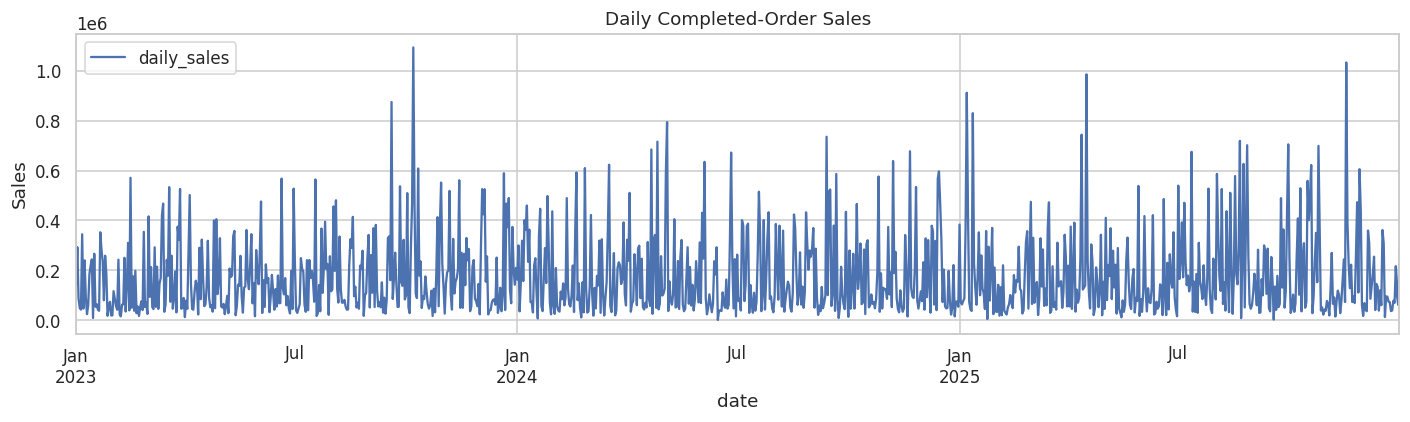

In [3]:
completed = df.loc[df['order_status'].astype(str).str.strip().str.lower().eq('completed')].copy()
if completed.empty:
    raise ValueError('No completed orders found.')
completed['date'] = completed['order_date'].dt.normalize()
calendar = pd.date_range(df['order_date'].min().normalize(), df['order_date'].max().normalize(), freq='D')
sales = completed.groupby('date')['sales'].sum().reindex(calendar, fill_value=0).rename('daily_sales')
daily = sales.rename_axis('date').reset_index()
print('Completed orders:', len(completed), '| Calendar days:', len(daily))
display(sales.describe().to_frame())
daily.plot(x='date', y='daily_sales', figsize=(13, 4), title='Daily Completed-Order Sales')
plt.ylabel('Sales'); plt.tight_layout(); plt.show()

## 4. Historical and calendar features
No profit, same-day quantity, same-day price, or future outcomes are predictors. All rolling statistics start with `shift(1)`. Long windows capture a more stable sales level; median windows are less sensitive to peaks.

In [4]:
features = daily.copy()
for name, values in {
    'day_of_week': daily['date'].dt.dayofweek,
    'month': daily['date'].dt.month,
    'day_of_year': daily['date'].dt.dayofyear,
    'time_index': np.arange(len(daily)),
}.items():
    features[name] = values
for name, period in [('day_of_week', 7), ('month', 12), ('day_of_year', 365.25)]:
    features[name + '_sin'] = np.sin(2 * np.pi * features[name] / period)
    features[name + '_cos'] = np.cos(2 * np.pi * features[name] / period)
for lag in [1, 7, 14, 28]:
    features[f'sales_lag_{lag}'] = sales.shift(lag).to_numpy()
past = sales.shift(1)
for window in [7, 14, 28, 56]:
    for statistic in ['mean', 'median', 'std']:
        features[f'sales_rolling_{statistic}_{window}'] = getattr(past.rolling(window), statistic)().to_numpy()
features['expanding_mean'] = past.expanding(min_periods=56).mean().to_numpy()
model_data = features.dropna().reset_index(drop=True)
feature_columns = [c for c in model_data if c not in ['date', 'daily_sales']]
if len(model_data) < 200:
    raise ValueError('At least 256 calendar days are required for this evaluation design.')
split = int(len(model_data) * 0.8)
train, test = model_data.iloc[:split].copy(), model_data.iloc[split:].copy()
X_train, y_train = train[feature_columns], train['daily_sales']
X_test, y_test = test[feature_columns], test['daily_sales']
print('Train:', len(train), train['date'].min(), 'to', train['date'].max())
print('Test:', len(test), test['date'].min(), 'to', test['date'].max())
print('Features:', len(feature_columns))

Train: 832 2023-02-26 00:00:00 to 2025-06-06 00:00:00
Test: 208 2025-06-07 00:00:00 to 2025-12-31 00:00:00
Features: 27


## 5. Candidate models and historical benchmarks
Yesterday, last week, trailing means, and a historical mean are useful checks on whether machine learning adds value. Ridge regularizes correlated lag features. Histogram gradient boosting and Random Forest provide nonlinear candidates. All candidates are selected by the same validation RMSE; test performance never determines the winner.

In [5]:
from sklearn.model_selection import GridSearchCV
# Tune using expanding-window folds only within the training period.
searches = {
    'Ridge': GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
        {'ridge__alpha':[10.,100.,1000.,10000.]}, cv=TimeSeriesSplit(n_splits=4), scoring='neg_root_mean_squared_error', n_jobs=1),
    'Random Forest': GridSearchCV(RandomForestRegressor(n_estimators=150,max_features=.7,random_state=RANDOM_STATE,n_jobs=-1),
        {'max_depth':[4,8], 'min_samples_leaf':[5,20]}, cv=TimeSeriesSplit(n_splits=4), scoring='neg_root_mean_squared_error', n_jobs=1),
    'Gradient Boosting': GridSearchCV(HistGradientBoostingRegressor(max_iter=100,min_samples_leaf=30,learning_rate=.05,l2_regularization=100.,random_state=RANDOM_STATE),
        {'max_leaf_nodes':[3,7]}, cv=TimeSeriesSplit(n_splits=4), scoring='neg_root_mean_squared_error', n_jobs=1)
}
for name, search in searches.items():
    search.fit(X_train,y_train)
    print(name, 'best parameters:',search.best_params_,'| validation RMSE:',round(-search.best_score_,2))
estimators={'Linear Regression':make_pipeline(StandardScaler(),LinearRegression())}
for name, search in searches.items():estimators['Tuned '+name]=search.best_estimator_
benchmarks={'Yesterday':'sales_lag_1','Last week':'sales_lag_7','Trailing 28-day mean':'sales_rolling_mean_28','Trailing 56-day mean':'sales_rolling_mean_56','Historical expanding mean':'expanding_mean','Training mean':None}
def predict_candidate(name,fit_X,fit_y,predict_X):
    if name in benchmarks:
        col=benchmarks[name]
        pred=np.full(len(predict_X),fit_y.mean()) if col is None else predict_X[col].to_numpy()
        return np.maximum(0,pred),None
    fitted=clone(estimators[name]).fit(fit_X,fit_y)
    return np.maximum(0,fitted.predict(predict_X)),fitted

def scores(y,pred):
    return {'MAE':mean_absolute_error(y,pred),'RMSE':np.sqrt(mean_squared_error(y,pred)),'R2':r2_score(y,pred)}
cv=TimeSeriesSplit(n_splits=4)
validation_rows=[]
for name,col in benchmarks.items():
    ys,ps=[],[]
    for fi,vi in cv.split(X_train):
        pred,_=predict_candidate(name,X_train.iloc[fi],y_train.iloc[fi],X_train.iloc[vi])
        ys.extend(y_train.iloc[vi]);ps.extend(pred)
    validation_rows.append({'Model':name,'RMSE':np.mean([scores(y_train.iloc[vi],predict_candidate(name,X_train.iloc[fi],y_train.iloc[fi],X_train.iloc[vi])[0])['RMSE'] for fi,vi in cv.split(X_train)])})
linear_rmse=[]
for fi,vi in cv.split(X_train):linear_rmse.append(scores(y_train.iloc[vi],predict_candidate('Linear Regression',X_train.iloc[fi],y_train.iloc[fi],X_train.iloc[vi])[0])['RMSE'])
validation_rows.append({'Model':'Linear Regression','RMSE':np.mean(linear_rmse)})
for name,search in searches.items():validation_rows.append({'Model':'Tuned '+name,'RMSE':-search.best_score_})
validation=pd.DataFrame(validation_rows).sort_values('RMSE').reset_index(drop=True)
best_name=validation.iloc[0]['Model']
best_ml_name=next(name for name in validation.Model if name in estimators)
candidates=list(benchmarks)+list(estimators)
print('Selected overall:',best_name,'| Best ML candidate:',best_ml_name)
display(validation.round(3))


Ridge best parameters: {'ridge__alpha': 10000.0} | validation RMSE: 166812.17
Random Forest best parameters: {'max_depth': 4, 'min_samples_leaf': 20} | validation RMSE: 169886.56
Gradient Boosting best parameters: {'max_leaf_nodes': 3} | validation RMSE: 168536.45
Selected overall: Training mean | Best ML candidate: Tuned Ridge


                       Model         RMSE
0              Training mean   166628.397
1  Historical expanding mean   166670.859
2                Tuned Ridge   166812.174
3       Trailing 56-day mean   167474.799
4    Tuned Gradient Boosting   168536.452
5       Trailing 28-day mean   169326.394
6        Tuned Random Forest   169886.564
7                  Yesterday   227409.520
8                  Last week   245302.477
9          Linear Regression  1049613.995

## 6. Final test evaluation
The chosen candidate is now fitted on all training days. Other test results are diagnostic comparisons only. Keep the selected model even if another candidate happens to score better on this test period. R² can remain negative when daily demand is largely unpredictable.

Validation-selected model: Training mean


                       Model  Selected_by_validation         MAE        RMSE     R2
0                  Yesterday                   False  177273.563  242016.956 -0.819
1                  Last week                   False  169598.791  234591.434 -0.709
2       Trailing 28-day mean                   False  141551.593  185203.570 -0.065
3       Trailing 56-day mean                   False  138206.634  180421.230 -0.011
4  Historical expanding mean                   False  134439.035  180127.917 -0.007
5              Training mean                    True  134709.962  179908.085 -0.005
6          Linear Regression                   False  135681.309  186999.450 -0.086
7                Tuned Ridge                   False  134895.464  180204.154 -0.008
8        Tuned Random Forest                   False  136224.910  185122.991 -0.064
9    Tuned Gradient Boosting                   False  134949.398  184704.230 -0.059

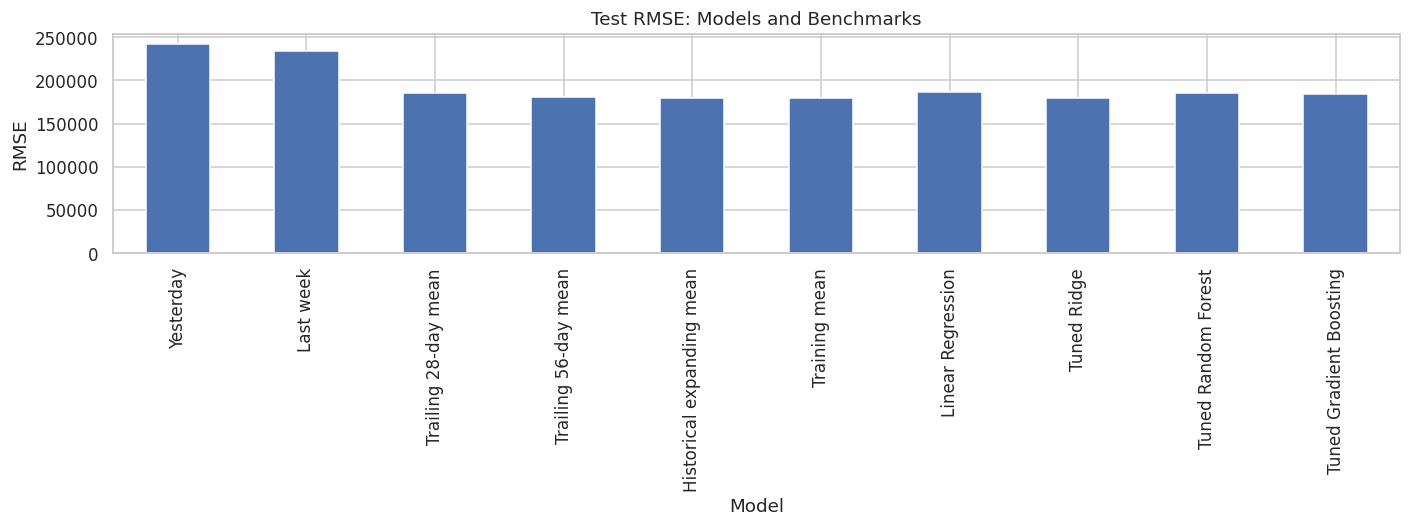

In [6]:
test_rows, fitted_models, test_forecasts = [], {}, {}
for name in candidates:
    pred, fitted = predict_candidate(name, X_train, y_train, X_test)
    fitted_models[name], test_forecasts[name] = fitted, pred
    test_rows.append({'Model': name, 'Selected_by_validation': name == best_name, **scores(y_test, pred)})
comparison = pd.DataFrame(test_rows)
predictions = test_forecasts[best_name]
selected_scores = scores(y_test, predictions)
print('Validation-selected model:', best_name)
display(comparison.round(3))
comparison.plot.bar(x='Model', y='RMSE', figsize=(13, 5), legend=False, title='Test RMSE: Models and Benchmarks')
plt.ylabel('RMSE'); plt.tight_layout(); plt.show()

## 7. Actual versus predicted and residual analysis

        date  actual_sales  predicted_sales   residual  absolute_error
0 2025-06-07      73548.66        175865.73 -102317.07       102317.07
1 2025-06-08      68309.69        175865.73 -107556.04       107556.04
2 2025-06-09     126930.69        175865.73  -48935.04        48935.04
3 2025-06-10     421021.59        175865.73  245155.86       245155.86
4 2025-06-11      22786.64        175865.73 -153079.09       153079.09
5 2025-06-12      27151.97        175865.73 -148713.76       148713.76
6 2025-06-13      73946.07        175865.73 -101919.66       101919.66
7 2025-06-14      45987.91        175865.73 -129877.82       129877.82
8 2025-06-15      56626.62        175865.73 -119239.11       119239.11
9 2025-06-16     143640.73        175865.73  -32225.00        32225.00

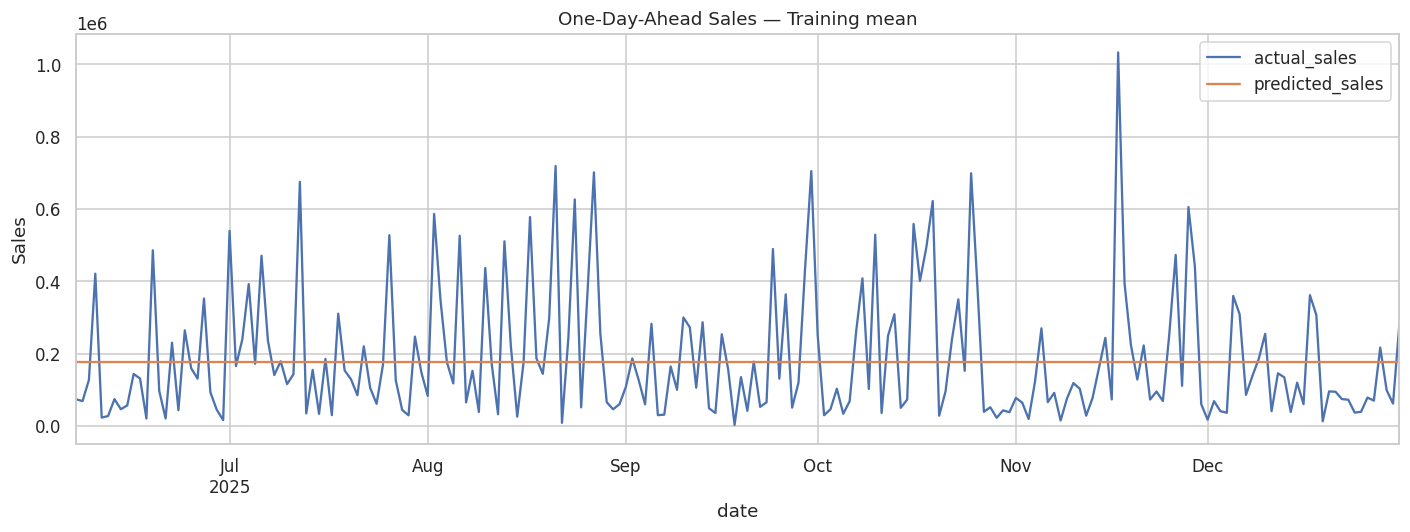

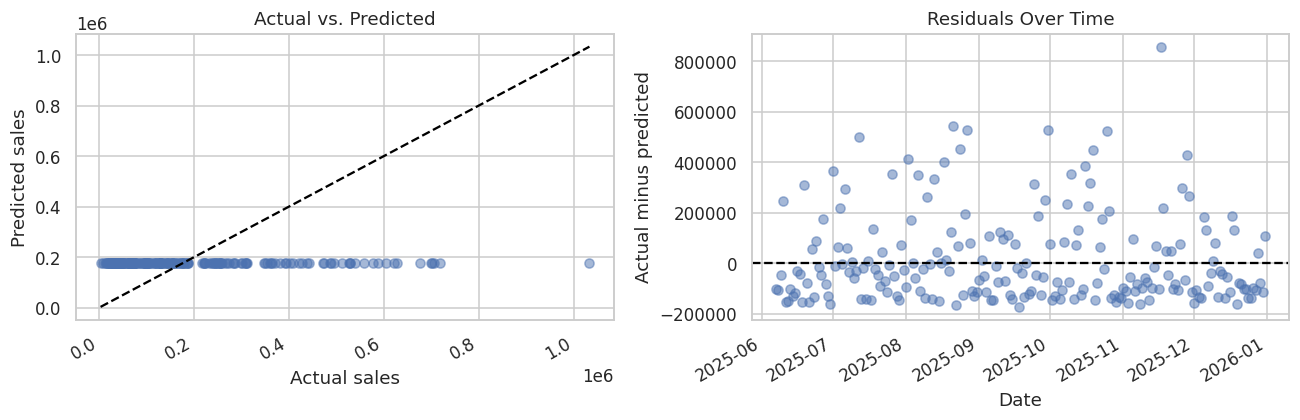

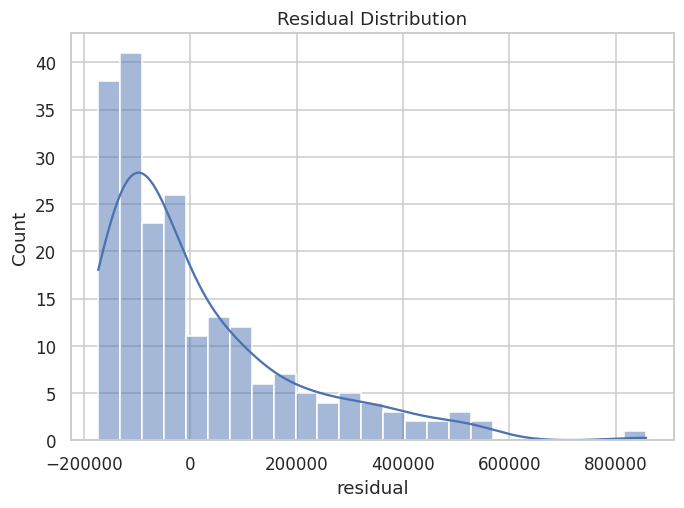

In [7]:
prediction_results = pd.DataFrame({'date': test['date'].to_numpy(),
    'actual_sales': y_test.to_numpy(), 'predicted_sales': predictions})
prediction_results['residual'] = prediction_results['actual_sales'] - prediction_results['predicted_sales']
prediction_results['absolute_error'] = prediction_results['residual'].abs()
display(prediction_results.head(10).round(2))
prediction_results.plot(x='date', y=['actual_sales', 'predicted_sales'], figsize=(13, 5), title=f'One-Day-Ahead Sales — {best_name}')
plt.ylabel('Sales'); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(prediction_results['actual_sales'], predictions, alpha=0.5)
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].plot(limits, limits, '--', color='black')
axes[0].set(xlabel='Actual sales', ylabel='Predicted sales', title='Actual vs. Predicted')
axes[1].scatter(prediction_results['date'], prediction_results['residual'], alpha=0.5)
axes[1].axhline(0, linestyle='--', color='black')
axes[1].set(xlabel='Date', ylabel='Actual minus predicted', title='Residuals Over Time')
fig.autofmt_xdate(); plt.tight_layout(); plt.show()
sns.histplot(prediction_results['residual'], bins=25, kde=True)
plt.title('Residual Distribution'); plt.tight_layout(); plt.show()

## 8. Tree-model feature importance
The tuned Random Forest chart fulfills the tree-based diagnostic requirement. A separate comparison shows the best validation-selected ML model even if a simple historical benchmark wins overall.

                    feature  importance
19     sales_rolling_std_14    0.131778
11              sales_lag_7    0.094997
8           day_of_year_sin    0.086735
16      sales_rolling_std_7    0.067178
26           expanding_mean    0.064769
10              sales_lag_1    0.057446
15   sales_rolling_median_7    0.053991
9           day_of_year_cos    0.043987
2               day_of_year    0.040279
25     sales_rolling_std_56    0.038287
12             sales_lag_14    0.034769
14     sales_rolling_mean_7    0.034451
23    sales_rolling_mean_56    0.028510
13             sales_lag_28    0.028455
21  sales_rolling_median_28    0.025353

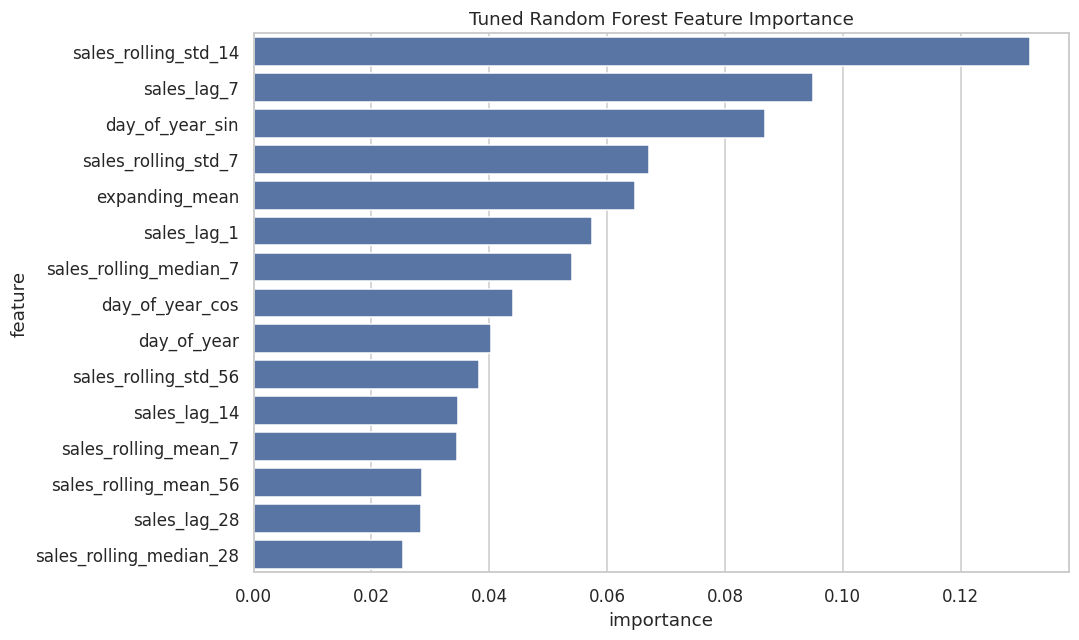

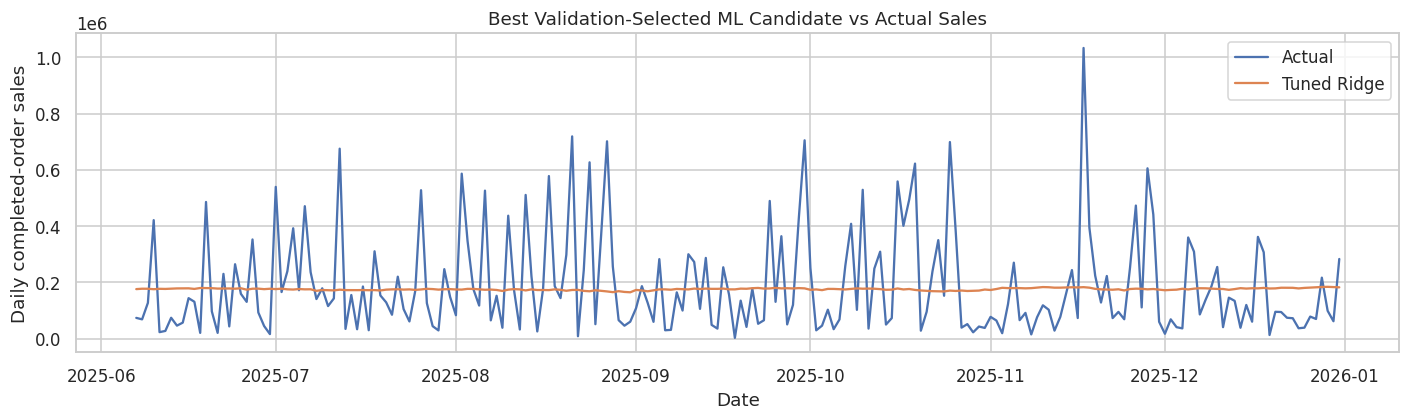

In [8]:
# Tree-based importance required by the assignment. This describes the fitted RF,
# not causality or evidence that it outperforms a benchmark.
importance_model=fitted_models['Tuned Random Forest']
importance=pd.DataFrame({'feature':feature_columns,'importance':importance_model.feature_importances_}).sort_values('importance',ascending=False)
display(importance.head(15))
plt.figure(figsize=(10,6));sns.barplot(data=importance.head(15),x='importance',y='feature')
plt.title('Tuned Random Forest Feature Importance');plt.tight_layout();plt.show()
# Also visualize the validation-selected ML candidate, even when a benchmark wins.
plt.figure(figsize=(13,4))
plt.plot(test['date'],y_test,label='Actual')
plt.plot(test['date'],test_forecasts[best_ml_name],label=best_ml_name)
plt.title('Best Validation-Selected ML Candidate vs Actual Sales')
plt.xlabel('Date');plt.ylabel('Daily completed-order sales');plt.legend();plt.tight_layout();plt.show()


## 9. Evidence-based conclusion
Results below are generated from this run. A negative R² means the predictions perform worse than a constant equal to the test-period mean (a retrospective reference, unavailable in advance). The training-mean benchmark is a deployable comparison. Weak accuracy is a valid finding: do not claim operational readiness or change the data to inflate scores.

In [9]:
print(f'Selected model: {best_name}')
print(f"Test MAE: {selected_scores['MAE']:,.2f}")
print(f"Test RMSE: {selected_scores['RMSE']:,.2f}")
print(f"Test R²: {selected_scores['R2']:.4f}")
training_mean_rmse = comparison.loc[comparison['Model'].eq('Training mean'), 'RMSE'].iloc[0]
print(f"RMSE improvement over training-mean benchmark: {100*(1-selected_scores['RMSE']/training_mean_rmse):.2f}%")
print(f"Mean residual: {prediction_results['residual'].mean():,.2f}; negative means average overprediction.")
if selected_scores['R2'] <= 0:
    print('Conclusion: daily forecasts remain weak. The workflow is complete, but reliable business forecasting is not established.')
else:
    print('Conclusion: positive test R² provides evidence of predictive signal on this period, with uncertainty on future periods.')
print('Use for staffing or inventory only after further validation; promotions, stockouts, and order-volume drivers may improve forecasts.')
print('Limitations: synthetic transactions, limited daily history, zero-fill assumption, and one-day-ahead evaluation using observed preceding days.')

Selected model: Training mean
Test MAE: 134,709.96
Test RMSE: 179,908.09
Test R²: -0.0049
RMSE improvement over training-mean benchmark: 0.00%
Mean residual: 12,601.60; negative means average overprediction.
Conclusion: daily forecasts remain weak. The workflow is complete, but reliable business forecasting is not established.
Use for staffing or inventory only after further validation; promotions, stockouts, and order-volume drivers may improve forecasts.
Limitations: synthetic transactions, limited daily history, zero-fill assumption, and one-day-ahead evaluation using observed preceding days.


## 10. Export results

In [10]:
validation.to_csv(OUTPUT_DIR / 'validation_model_comparison.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'model_evaluation_comparison.csv', index=False)
importance.to_csv(OUTPUT_DIR / 'feature_importance.csv', index=False)
prediction_results.to_csv(OUTPUT_DIR / 'actual_vs_predicted_sales.csv', index=False)
with (OUTPUT_DIR / 'evaluation_summary.json').open('w') as f:
    json.dump({'selected_model': best_name, 'selection_rule': 'lowest expanding-window validation RMSE',
        'test_metrics': {k: float(v) for k, v in selected_scores.items()},
        'test_start': str(test['date'].min().date()), 'test_end': str(test['date'].max().date())}, f, indent=2)
print('Saved results to:', OUTPUT_DIR)
for name in ['validation_model_comparison.csv', 'model_evaluation_comparison.csv', 'feature_importance.csv', 'actual_vs_predicted_sales.csv', 'evaluation_summary.json']:
    print('-', name)

Saved results to: /workspace/scratch/79371d245f93/retail-sales-week2/reports/model
- validation_model_comparison.csv
- model_evaluation_comparison.csv
- feature_importance.csv
- actual_vs_predicted_sales.csv
- evaluation_summary.json
